In [263]:
# script to model CBS data
# last update Peter Berrill 9/3/2025

# load in required packages
import numpy as np
import pandas as pd
import shap
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold, cross_validate, GroupKFold, StratifiedGroupKFold, RepeatedKFold, StratifiedKFold, GridSearchCV, KFold
from sklearn import metrics, linear_model
from xgboost import XGBClassifier, XGBRegressor
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import seaborn as sns

This notebook demonstrates a few things. 

1. Examining the set of predictor/independent variables to look for large correlation issues
2. Preparing data for modelling with OLS regression and GBDT models
3. Cross validation to estimate best hyperparameters in GBDT model
4. A repeated k-fold cross validation to estimate performance of the model robustly (without training on the whole dataset), during which we estimate average shap values (explainers for the GBDT model) and regression coefficients
5. Visualisation of variable influence and importance derived from the SHAP values

# Exploration of GHG

## Defining dependent & independent variables

In [264]:
year = ''

classification = 'income' #alternative: 'tenure', 'income'
if classification == 'income':
    lab = 'inc_lab'
    class_name = 'income level'
    class_name_short = 'income'
    class_name_long = 'equivalised income level'
    class_col = 'inc_decile'
else: #if tenure
    lab = 'tenure_lab'
    class_name = 'tenure'
    class_name_short = 'tenure'
    class_name_long = 'tenure'
    class_col = str('tenure'+year)

df2019 =pd.read_csv('data_input/output/use'+classification+'2019.csv', index_col=[0,1,2,3,4])
df2023 =pd.read_csv('data_input/output/use'+classification+'2023.csv', index_col=[0,1,2,3,4])
dep2019 = pd.read_csv('data_processed/ghg_annual_per_cap'+classification+'2023.csv', index_col=[0,1,2,3,4])
dep2023 = pd.read_csv('data_processed/ghg_annual_per_cap'+classification+'2023.csv', index_col=[0,1,2,3,4])

df2019.columns = df2019.columns.str.replace('2019', '')
df2023.columns = df2023.columns.str.replace('2023', '')
dep2019.columns = dep2019.columns.str.replace('2019', '')
dep2023.columns = dep2023.columns.str.replace('2023', '')

df = pd.concat([df2019,df2023], keys=['2019', "2023"], names=['year'], axis=0)
dep = pd.concat([dep2019,dep2023], keys=['2019', "2023"], names=['year'], axis=0)

df['kg_CO2e_per_capita'] = dep.sum(1) #total ghg footprint for housing
df['m3_gas_per_capita'] = df['gas'+year]/df['mean_hhd']
df['kWh_electricity_per_capita'] = df['netelectricity'+year]/df['mean_hhd']
df['pkm_car_per_capita'] = df['car_pkm']/df['mean_hhd']



df['mean_cars'] = (df['car_hhd']/df['n_adultmem'+year]) #normalising car ownership by number of households
df['heatpump_pc'] = (df['n_heatpump'+year]/df['n_hhd']).fillna(0)
df['districtheating_pc'] = (df['n_cityheating'+year]/df['n_hhd']).fillna(0)
if classification == 'tenure':
    df['tenure'+year].replace(2, 3.1, inplace=True)
    df['tenure'+year].replace(3, 2.1, inplace=True)
    df['tenure'+year].replace(3.1, 3, inplace=True)
    df['tenure'+year].replace(2.1, 2, inplace=True)
df.reset_index(inplace=True)
df.columns

#apply clear labels
renaming_map = {'typology4_'+year:'building_type',
                 'const_cat'+year:'building_age',
                 'density'+year:'population_density',
                  'mean_hhd':'household_size',
                'size'+year+'pp_w1':'dwelling_size',
                'mean_cars':'cars_per_adult',
                }
df = df.rename(columns=renaming_map)
df = df.rename(columns={'dwelling_size':'m2_floorarea_per_capita'})

df['building_age'].replace([1,2,3,4,5,6], [6,5,4,3,2,1], inplace=True)
df['population_density'].replace([1,2,3,4,5,6], [6,5,4,3,2,1], inplace=True)

In [265]:
# collect here the independent (predictor) variables, both in original format and with all categoricals converted to numeric
ind_vars=[lab,'typology_lab','const_lab','density_lab',#'distance_train'+year,'distance_depstore'+year,
          'distance_supermarket'+year,'distance_middleschool'+year,
          'mean_hhd',#'size'+year+'pp_w1',#'mean_cars',
          #'districtheating_pc', 
          #'heatpump_pc',
          ]
ind_vars_num=[class_col,'building_type','building_age','population_density',#'distance_train'+year,'distance_depstore'+year,
              'distance_supermarket'+year,'distance_middleschool'+year,
          'household_size',#'dwelling_size',#'cars_per_adult',
          #'districtheating_pc', 
          #'heatpump_pc',
          ]
dep_var= 'm2_floorarea_per_capita' #'m3_gas_per_capita' #'pkm_car_per_capita' #'kWh_electricity_per_capita'  #'kg_CO2e_per_capita' #'netelectricity'+year

## Checking for multicollinearity

In [266]:
# check for correlation among predictor variables, and variance inflation factor - which indicates how big an issue multicollinearity is for each variable.
# preferable to keep VIF < ~5 when possible

# all variables, a combination of the numeric independent variables and the dependent variable
all_var=ind_vars_num.copy()
all_var.append(dep_var)
df0=df.loc[:,all_var]

# drop rows with NA values. We do this after defining df0, because if we did it with the whole df we would lose rows due to NAs that are not in the variables we are interested in
df0=df0.dropna()
X=df0.loc[:,ind_vars_num]
X_selc = add_constant(X)
vif=pd.Series([variance_inflation_factor(X_selc.values, i) for i in range(X_selc.shape[1])], index=X_selc.columns)
vif=vif.to_frame().reset_index()
vif.columns=['Feature','VIF']
corr = X.corr()
print(vif)
corr.abs().style.format(precision=3).background_gradient(cmap='coolwarm')

                 Feature         VIF
0                  const  154.414261
1             inc_decile    1.365220
2          building_type    1.634515
3           building_age    1.105260
4     population_density    4.242968
5   distance_supermarket    2.576782
6  distance_middleschool    4.364375
7         household_size    2.162124


,inc_decile,building_type,building_age,population_density,distance_supermarket,distance_middleschool,household_size
inc_decile,1.000,0.012,0.005,0.015,0.059,0.028,0.425
building_type,0.012,1.000,0.008,0.031,0.213,0.057,0.545
building_age,0.005,0.008,1.000,0.012,0.111,0.026,0.211
population_density,0.015,0.031,0.012,1.000,0.707,0.862,0.025
distance_supermarket,0.059,0.213,0.111,0.707,1.000,0.724,0.228
distance_middleschool,0.028,0.057,0.026,0.862,0.724,1.000,0.011
household_size,0.425,0.545,0.211,0.025,0.228,0.011,1.000


In [267]:
# updating variables

# without middleschool and department store
ind_vars=[lab,'typology_lab','const_lab','density_lab',#'distance_train'+year,'distance_depstore'+year,
          'distance_supermarket'+year,'distance_middleschool'+year,
          'mean_hhd',#'size'+year+'pp_w1',#'mean_cars',
          #'districtheating_pc', 
          #'heatpump_pc',
          ]
ind_vars_num=[class_col,'building_type','building_age','population_density',#'distance_train'+year,'distance_depstore'+year,
              'distance_supermarket'+year,'distance_middleschool'+year,
          'household_size',#'dwelling_size',#'cars_per_adult',
          #'districtheating_pc', 
          #'heatpump_pc',
          ]


all_var=ind_vars_num.copy()
all_var.append(dep_var)
df0=df.loc[:,all_var]
df0=df0.dropna()

# additional check for multicollinearity
X=df0.loc[:,ind_vars_num]
X_selc = add_constant(X)
vif=pd.Series([variance_inflation_factor(X_selc.values, i) for i in range(X_selc.shape[1])], index=X_selc.columns)
vif=vif.to_frame().reset_index()
vif.columns=['Feature','VIF']
corr = X.corr()
print(vif)
corr.abs().style.format(precision=3).background_gradient(cmap='coolwarm')

                 Feature         VIF
0                  const  154.414261
1             inc_decile    1.365220
2          building_type    1.634515
3           building_age    1.105260
4     population_density    4.242968
5   distance_supermarket    2.576782
6  distance_middleschool    4.364375
7         household_size    2.162124


,inc_decile,building_type,building_age,population_density,distance_supermarket,distance_middleschool,household_size
inc_decile,1.000,0.012,0.005,0.015,0.059,0.028,0.425
building_type,0.012,1.000,0.008,0.031,0.213,0.057,0.545
building_age,0.005,0.008,1.000,0.012,0.111,0.026,0.211
population_density,0.015,0.031,0.012,1.000,0.707,0.862,0.025
distance_supermarket,0.059,0.213,0.111,0.707,1.000,0.724,0.228
distance_middleschool,0.028,0.057,0.026,0.862,0.724,1.000,0.011
household_size,0.425,0.545,0.211,0.025,0.228,0.011,1.000


## Dummify categorical variables

In [268]:
#for ordinal analysis
df1=df0.copy() # this is the one for OLS, which can handle categorical variables
y=df0[dep_var]
X=df0.drop(columns=dep_var)

# define the OLS regression equation
form_str=dep_var+" ~ "+' + '.join(ind_vars_num)
#form_str=dep_var+" ~ "+class_col+" + typology4_"+year+" + const_cat"+year+" + density"+year+" + mean_hhd + size"+year+"pp_w1 + districtheating_pc + heatpump_pc"

In [269]:
# # for the categorical variables in the GBDT model, we should dummify them: income, typology, construction year, and density

# # append the dependent (outcome) variables to the list of independent variables (categorical version)
# all_var=ind_vars.copy()
# all_var.append(dep_var)

# df0=df.loc[:,all_var]
# # remove NAs
# df0=df0.dropna() 
# df1=df0.copy() # this is the one for OLS, which can handle categorical variables

# # convert  all categorical variables to dummies
# df_Cat=df0.loc[:,[lab,'typology_lab','const_lab','density_lab']]
# for col in df_Cat:
#     dum=pd.get_dummies(df0[[col]])
#     df0 = pd.concat([df0, dum], axis = 1)

# # this is the df needed for ML models, e.g. xgboost
# df0.drop(columns=[lab,'typology_lab','const_lab','density_lab'],inplace=True)
# y=df0[dep_var]
# X=df0.drop(columns=dep_var)
# X

# # define the OLS regression equation
# form_str=dep_var+" ~ C("+lab+",Treatment(reference='decile 1 (poorest)')) + C(typology_lab,Treatment(reference='detached')) + C(const_lab,Treatment(reference='pre 1945')) + C(density_lab,Treatment(reference='rural'))  + distance_train"+year+" + distance_depstore"+year+" + distance_supermarket"+year+" + mean_hhd + size"+year+"pp_w1 + mean_cars"

## GBTD Model parameter calibration via cross validation

In [270]:
# do a cross validation to estimate the best hyperparameters for use in a GBDT model
# here we are seeing the values of hyperparameters 'learning rate', 'number of estimators' i.e. number of trees, and 'max depth' (max amount of interaction between variables considered)
# which give the best performance (prediction on unseen values). basically it is fine tuning to give a gradient boosting tree model with best predictive power

cv = RepeatedKFold(n_splits=5,n_repeats=8,random_state=1)
PS = {"learning_rate": [0.01, 0.05,0.1,0.2], 
        "n_estimators": [100,200, 300],
        "max_depth":[2,3,4]}

tuning_all = GridSearchCV(estimator=XGBRegressor(verbosity=0), param_grid=PS, cv=cv, scoring="r2",return_train_score=True)
tuning_all.fit(X,y)

print('best hyper-parameters identified by HPO')
print(tuning_all.best_params_)
print('r2 with best hyper-parameters')
print(tuning_all.best_score_)
cv_res_all=tuning_all.cv_results_

n_parameter_all = tuning_all.best_params_['n_estimators']
lr_parameter_all = tuning_all.best_params_['learning_rate']
md_parameter_all = tuning_all.best_params_['max_depth']

best hyper-parameters identified by HPO
{'learning_rate': 0.2, 'max_depth': 4, 'n_estimators': 300}
r2 with best hyper-parameters
0.9329919677916351


In [279]:
# only need to do the above step once, it is time intensive
# electricity: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300}
# ghg categorical: {'learning_rate': 0.2, 'max_depth': 4, 'n_estimators': 300}
# ghg ordinal: {'learning_rate': 0.2, 'max_depth': 4, 'n_estimators': 300}
# ghg ordinal tenure: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300}
# gas ordinal income: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 300}
# gas ordinal income w/o building type: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}
# gas ordinal income 2023: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300}
# electricity ordinal income 2019: {'learning_rate': 0.2, 'max_depth': 4, 'n_estimators': 300}
n_parameter_all = 300
lr_parameter_all = 0.2
md_parameter_all = 4

In [280]:
# then we run our models (OLS regression and xgboost) numerous times, each time with a model trained on 80% of the data and tested on the remaining 20%
# We collecte and estimate average regression coefficients and average shap values from the OLS and xgboost models respectively

# define a cross validation function for splitting up the dataset into train and test sets. 
# this is repeated a number of times (5 here)
cv = RepeatedKFold(n_splits=5,n_repeats=5,random_state=2)

# predefine some lists & dataframes
y_predict = pd.DataFrame()
y_predict2 = pd.DataFrame()
y_test = pd.DataFrame()
y_test2 = pd.DataFrame()
summ_table_list=[]

shap_values= pd.DataFrame() 

model = XGBRegressor(
max_depth=md_parameter_all, 
n_estimators=n_parameter_all, 
learning_rate=lr_parameter_all)

# if doing the repeated cv and creation of shap values, pre-define lists to store r2 values
r2ml=[]
r2lr=[]

for train_idx, test_idx in cv.split(X): # select here 
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test_fold = y.iloc[train_idx], y.iloc[test_idx]
        df_train, df_test = df1.iloc[train_idx], df1.iloc[test_idx] 
        y_test_fold2=df_test[dep_var]

        # train & predict GBDT model
        model.fit(X_train, y_train, verbose=False, eval_set=[(X_train, y_train), (X_test, y_test_fold)])
        y_predict_fold = pd.Series(model.predict(X_test), index=X_test.index)
        r2ml.extend([metrics.r2_score(y_test_fold.array, y_predict_fold.array)])
        # explain
        explainer = shap.TreeExplainer(model)
        shap_values_fold = explainer.shap_values(X_test,check_additivity=False)
        shap_values_fold = pd.DataFrame(shap_values_fold, index=X_test.index, columns=X.columns) 

        y_predict = pd.concat([y_predict, y_predict_fold], axis=0)
        y_test = pd.concat([y_test, y_test_fold], axis=0)

        shap_values = pd.concat([shap_values, shap_values_fold], axis=0)
        
        # estimate OLS model
        lin_reg = smf.ols(form_str, data=df_train).fit()
        yhat=np.asarray(lin_reg.predict(df_test.drop(columns=dep_var)))
        y_predict_fold2 = pd.Series(yhat, index=df_test.index)
        y_predict2 = pd.concat([y_predict2, y_predict_fold2], axis=0)
        y_test2 = pd.concat([y_test2, y_test_fold2], axis=0)
        
        r2lr.extend([metrics.r2_score(y_test_fold.array, y_predict_fold2.array)])

        # get the coefficents and p values of the regression
        coeff=lin_reg.params.reset_index()
        coeff.rename(columns={'index':'param',0:'coefficient'},inplace=True)
        pval=lin_reg.pvalues.reset_index()
        pval.rename(columns={'index':'param',0:'p'},inplace=True)
        summ_table=pd.concat([coeff,pval['p']],axis=1)

        st_list_fold=[summ_table.drop(columns='param').to_numpy()]
        summ_table_list.append(st_list_fold)

# save the summary regression table with average coefficients
mdarray=np.array(summ_table_list).squeeze()
means=np.nanmean(mdarray,axis=0)
means_df=pd.DataFrame(data=np.hstack((np.reshape(summ_table['param'].to_numpy(),(len(summ_table),1)),means)),columns=summ_table.columns.values)
means_df.to_csv('data_processed/OLS_summary_'+dep_var+year+classification+'.csv',index=False)

y_test = y_test.squeeze(axis=1)
y_test2 = y_test2.squeeze(axis=1)
y_predict = y_predict.squeeze(axis=1)
y_predict2 = y_predict2.squeeze(axis=1)
r2_model=metrics.r2_score(y_test, y_predict)
r2_model_reg=metrics.r2_score(y_test2, y_predict2)

# get the average importance ranking, either manually or using the shap built-in functions (can be slightly different results).
shap_values_abs=abs(shap_values)
shap_sum = shap_values_abs.mean(axis=0)
importance_df = pd.DataFrame([shap_sum]).T
importance_df.reset_index(inplace=True)
importance_df.rename(columns={'index':'feature',0:'shap_importance'},inplace=True)
importance_df = importance_df.sort_values('shap_importance', ascending=False)
importance_df['cont_pc']=100*importance_df['shap_importance']/importance_df['shap_importance'].sum()
importance_df.to_csv('data_processed/SHAP_summary_'+dep_var+year+classification+'.csv',index=False)

# summarise mean importance as estimated by shap values
shap_values=shap_values.sort_index()
shap_values.reset_index(inplace=True)
shap_values=shap_values.groupby('index').mean().reset_index()
shap_values.drop(columns=['index'],inplace=True)
shap_values.to_csv('data_processed/SHAP_values_'+dep_var+year+classification+'.csv',index=False)

# print and compare the peformance of the gradient boosting and OLS models
print('GBDT Model r2: ')
print(r2_model)
print('LR Model r2: ')
print(r2_model_reg)


GBDT Model r2: 
0.9331608228990863
LR Model r2: 
0.6331469195729709


## Display results

In [284]:
# OLS regression results
means_df.sort_index().to_excel("data_processed/results_OLS_"+dep_var+classification+".xlsx", sheet_name=str(round(r2_model_reg,4)))

In [285]:
importance_df.sort_index().to_excel("data_processed/results_XGB_"+dep_var+classification+".xlsx", sheet_name=str(round(r2_model,4)))

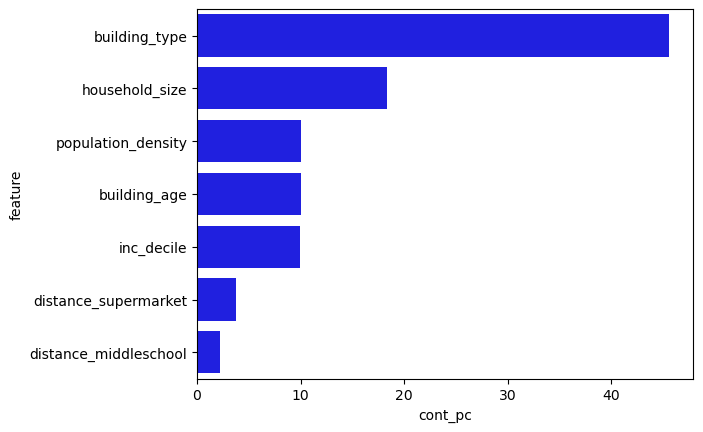

100%|===================| 11765/11789 [01:40<00:00]        

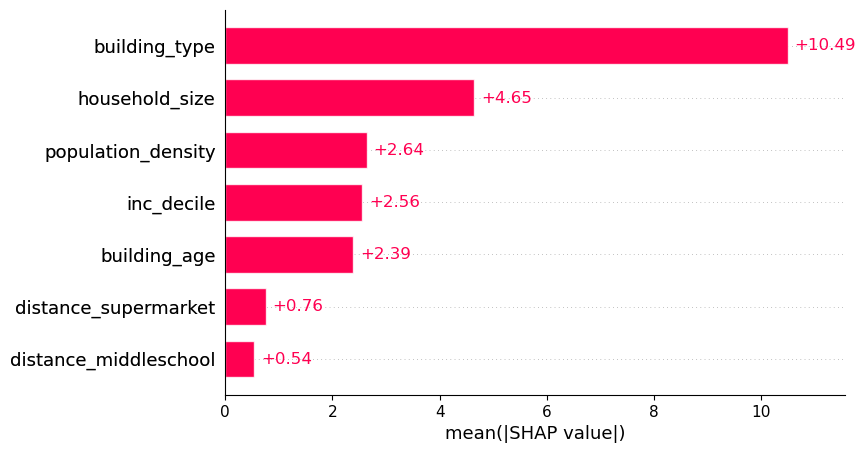

<Figure size 640x480 with 0 Axes>

In [275]:
# plot barlot of importance of each variable to the predicted outcome in the GBDT, measured in contribution percent
# this shows us the importance, but not the direction of influence of each variable
sns.barplot(data=importance_df.iloc[:12,], x='cont_pc', y='feature',color='blue')
plt.show()
plt.savefig('visualisations/barchart_shap_contribution_pc_'+dep_var+year+classification+'.svg')

# then the built in approach for showing variable importance, calculated different to the manual approach so can give different outputs, but tends to be broadly similar.
explainer = shap.Explainer(model, X)
shap_values_ex = explainer(X)
shap.plots.bar(shap_values_ex)
plt.show()
plt.savefig('visualisations/barchart_shap_mean_'+dep_var+year+classification+'.svg')

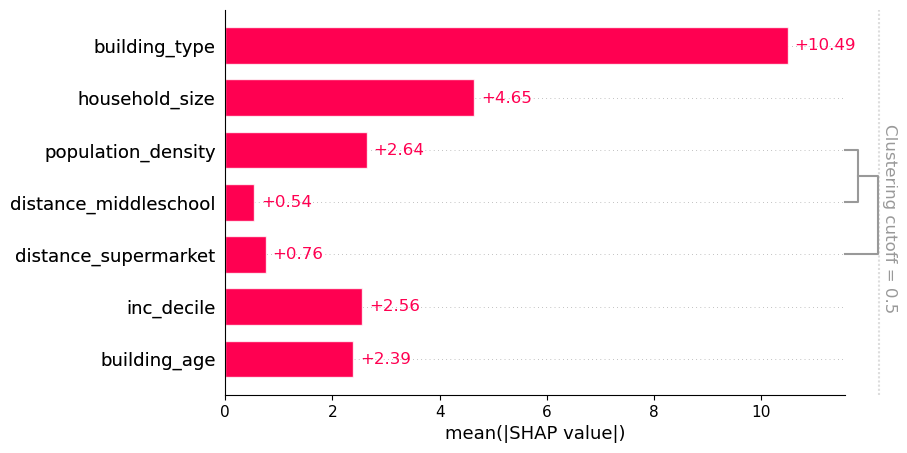

<Figure size 640x480 with 0 Axes>

In [276]:
#again the built in approach for showing variable imnportance, this time including clustering among related variabels
clustering = shap.utils.hclust(X, y)
shap.plots.bar(shap_values_ex, clustering=clustering)
plt.savefig('visualisations/barchart_shap_relatedvars_'+dep_var+year+classification+'.svg')

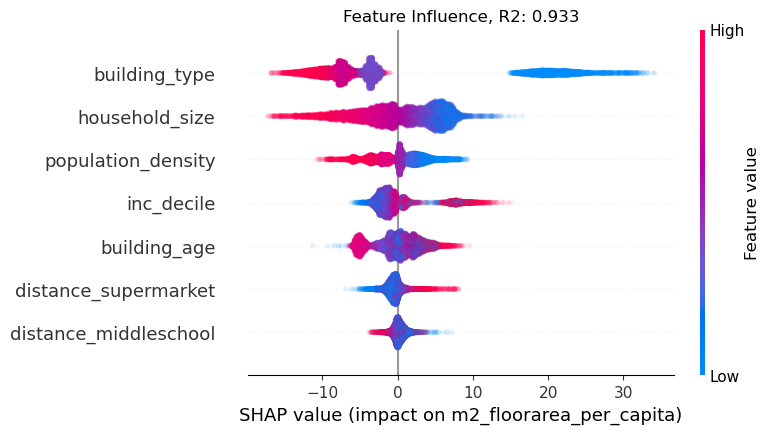

In [286]:
# plot influences over the range of each predictor value, ranked by importance
shap.summary_plot(shap_values.sort_index().to_numpy(), X.sort_index(),max_display=14,show=False, alpha=0.1)
plt.title('Feature Influence, R2: ' + round(r2_model,3).astype(str))
plt.xlabel("SHAP value (impact on "+dep_var+")")
plt.savefig('visualisations/violin_shap_range_'+dep_var+year+classification+'.png')

0
1
2
3
4
5
6


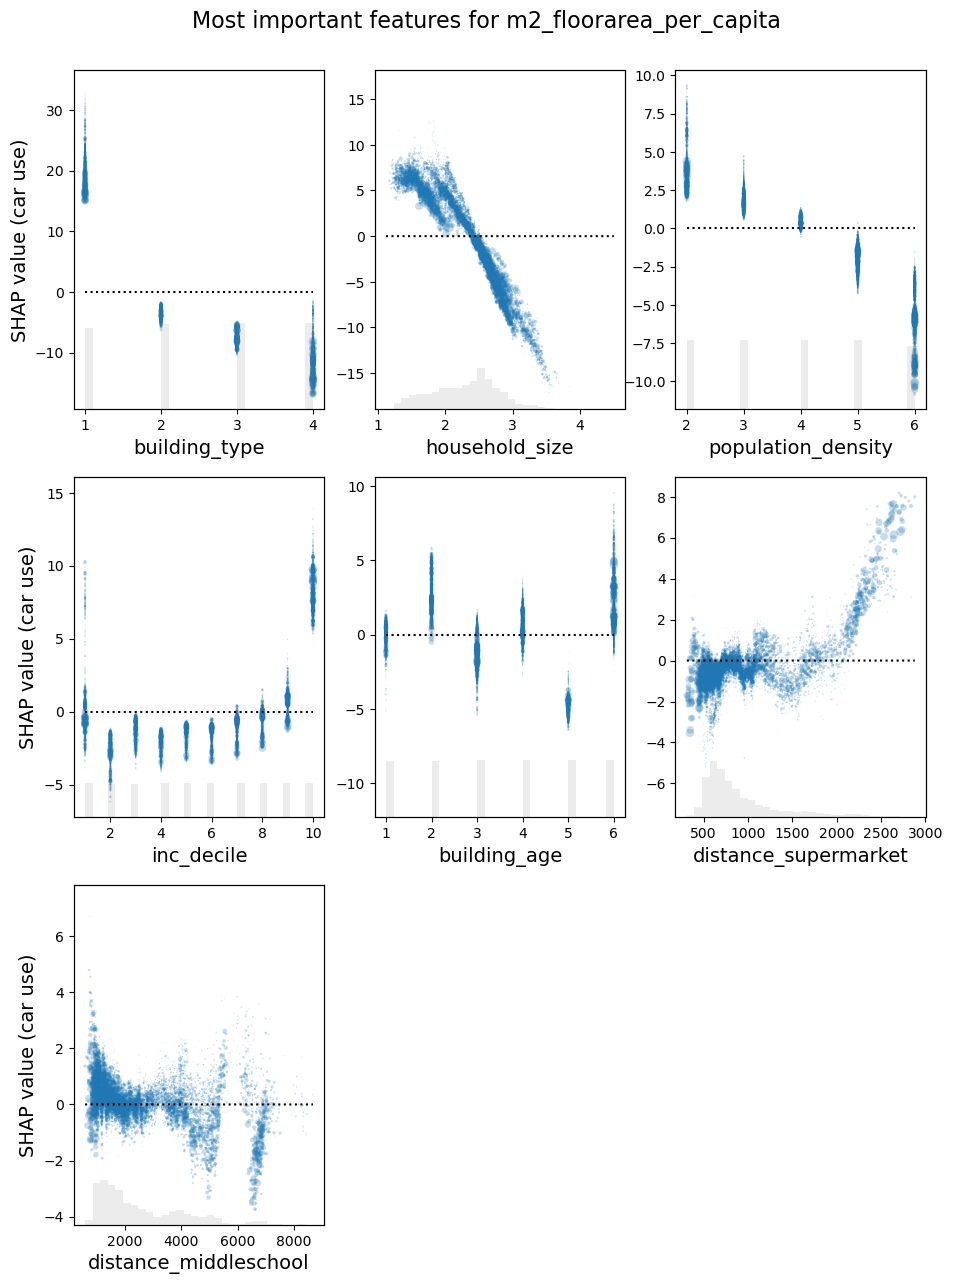

In [287]:
# then show the range of influences (shap values) over the range of the x values
# this has the benefit of allowing us to see the direction of influence and potential non-linear influence of variables
n=importance_df[:10].index

X.sort_index(inplace=True)
data=X.sort_index().iloc[:,n]
values=shap_values.sort_index().iloc[:,n]

xl=[]
yl=[]
y0=[]

for i in range(len(n)):
        dftemp=pd.DataFrame({'d':data.iloc[:,i],'v':values.iloc[:,i]})
        dftemp=dftemp.groupby('d')['v'].mean().reset_index()
        dftemp['v0']=0
        xl.append(dftemp['d'].values)
        yl.append(dftemp['v'].values)
        y0.append(dftemp['v0'].values)

# plot the conditional shap values (accounting for influences of other variables) for the top N most influential variables.
# here we choose the top 8. this can be changed by altering the range, and then the dimensions of the subplot (42 for 8, 32 for 6, etc.)

fig = plt.figure(figsize=(11,15))
for i in range(0,[len(ind_vars_num) if len(ind_vars_num)<=9 else 9][0]):
        print(i)
        ax1 = fig.add_subplot(331+i)
        xs=data.iloc[:,i]
        ys=values.iloc[:,i]
        x=xl[i]
        y1=y0[i]
        y2=yl[i]
        xlab=data.columns[i]

        ax1.scatter(xs,ys,alpha=0.25,s=df.dropna(subset=all_var).n_hhdmem.div(1000),linewidth=0)
        plt.plot(x,y1,'k:',label='zero')

        if i%3==0:
                ax1.set_ylabel('SHAP value (car use)',size=14)
        else:
                ax1.set_ylabel('')
        ax1.set_xlabel(xlab,size=14)

        ax2 = ax1.twinx() 
        if len(xs.unique())==2:
                ax2.hist(xs,bins=[-0.5,0.5,1.5], align='mid',color='gray',alpha=0.25)
                ax2.set_xticks([-.5,0,0.5,1,1.5])
        else:
                ax2.hist(xs,bins=30,color='gray',alpha=0.15)
                ax2.set_ylim(0,len(data))
        ax2.set_yticks([])
plt.suptitle("Most important features for "+dep_var,y=0.92,size=16)
plt.savefig('visualisations/scatter_shap_range_'+dep_var+year+classification+'.png')

# Example Exploration (case study: electricity consumption)